# [LAB-06] 데이터 시각화

## 6. Violin Plot

### #01 준비작업

1. 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *
import seaborn as sb

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.25


2. 데이터 가져오기

In [2]:
origin = load_data("stat_comp_grade")
origin.head()

📚 통계학 전공(STAT) 학생과 전산학 전공(COMP) 학생의 통계학 과목에 대한 중간고사 성적과 기말시험 성적 (출처: 방송통신대학교 통계학개론 수업내용에서 발췌)


,전공,중간고사,기말고사
0,STAT,34,86
1,STAT,50,77
2,STAT,75,74
3,COMP,76,96
4,COMP,61,78


### #02 ViolinPlot 시각화

1. 자동 인식 패턴

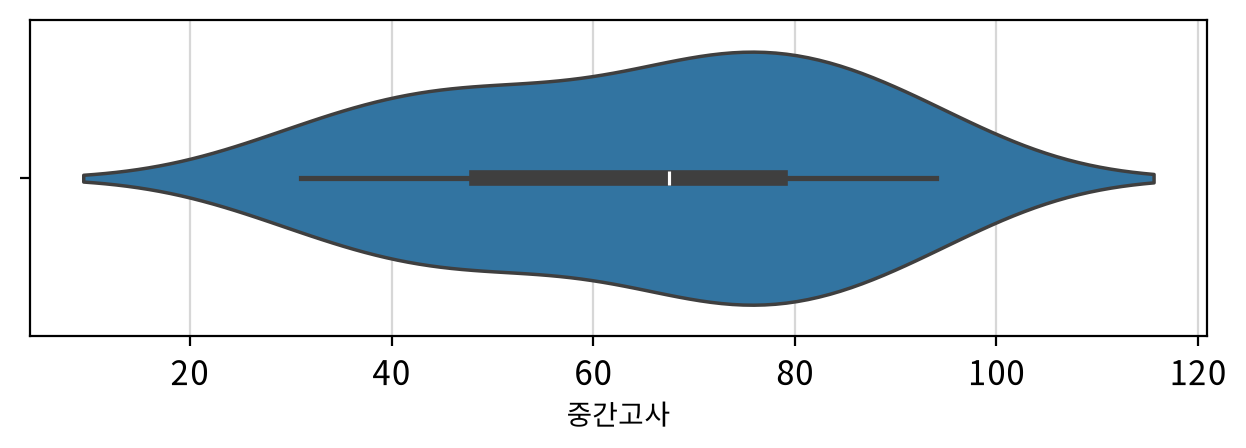

In [3]:
# 그래프 초기화
fig, ax = my_plot.init(width=640, height=240)

# 그래프 그리기
sb.violinplot(data=origin['중간고사'], orient="h")
ax.set_xlabel("중간고사", fontsize=10)

# 출력
my_plot.show()

> 인사이트
> - 중간고사 점수의 중심(중앙값)은 약 68~70점 부근에 위치함
> - 중간 50% 구간(IQR)은 대략 48~79점 범위로 보임
> - 분포 밀도는 70~80점대에서 가장 두껍게 나타나 해당 구간에 관측치가 많이 모여있음
> - 10~30점대 저득점 구간은 상대적으로 폭이 얇아 빈도가 낮게 나타남
> - 전체 분포 범위는 대략 10점대부터 110점대 중반까지 퍼져있음

2. 자동 인식 패턴에 DataFrame 지정을 위한 데이터 전처리

In [4]:
df = origin[['중간고사', '기말고사']]
df.head()

,중간고사,기말고사
0,34,86
1,50,77
2,75,74
3,76,96
4,61,78


3. 자동 인식 패턴에 DataFrame 지정

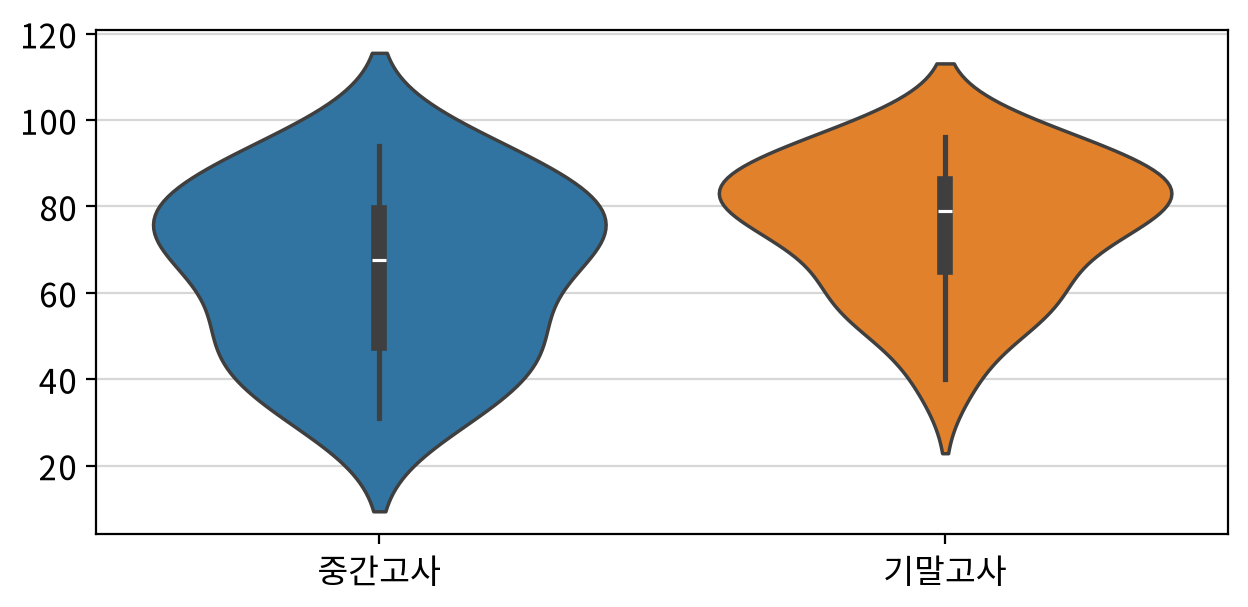

In [5]:
# 그래프 초기화
fig, ax = my_plot.init(width=640, height=320)

# 그래프 그리기
sb.violinplot(data=origin, orient="v")

# 출력
my_plot.show()

> 인사이트
> - **중앙값 비교**
>   - 기말고사 중앙값(약 80)이 중간고사 중앙값(약 67)보다 높게 나타남
> - **사분위 구간 비교**
>   - 중간고사 IQR은 대략 47~80, 기말고사 IQR은 대략 65~87로 보임
> - **분포 중심**
>   - 두 시험 모두 70~85 구간에서 폭이 두꺼워 관측치 밀도가 높은 구간으로 보임
> - **저득점 분포 차이**
>   - 중간고사는 30~50 구간 폭이 상대적으로 더 두껍고, 기말고사는 해당 구간이 더 얇게 나타남
> - **범위 비교**
>   - 중간고사 하한은 약 30, 기말고사 하한은 약 40으로 보이며 상한은 두 시험 모두 95~97 부근임

4. 개별 데이터 직접 지정 패턴

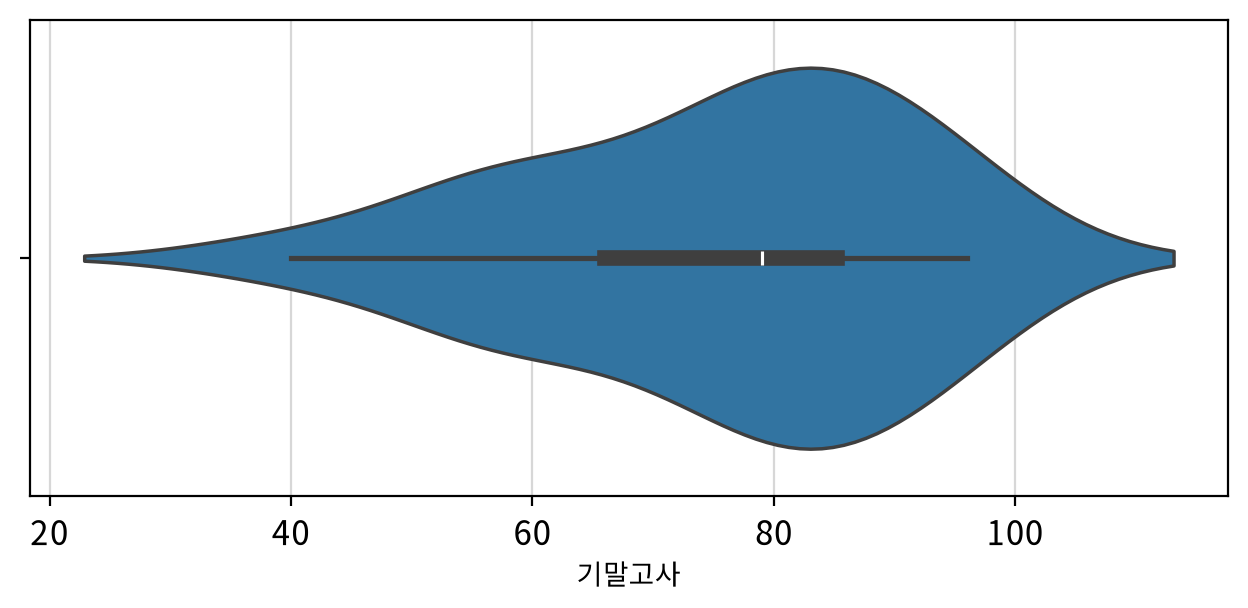

In [6]:
# 그래프 초기화
fig, ax = my_plot.init(width=640, height=320)

# 그래프 그리기
# -> 데이터가 x축으로 전개되므로 가로 방향 그래프가 된다.
sb.violinplot(x=df['기말고사'])
ax.set_xlabel("기말고사", fontsize=10)

# 출력
my_plot.show()

> 인사이트
> - 기말고사 중앙값은 약 79~80점 부근으로 보임
> - 중간 50% 구간(IQR)은 대략 66~86점 범위로 보임
> - 분포 밀도는 75~90점대에서 가장 두껍게 나타남
> - 40점대 이하와 100점대 이상 구간은 상대적으로 밀도가 낮음
> - 전체 분포 범위는 대략 40점부터 96점 부근까지 퍼져있음

5. 데이터프레임 + 컬럼명 패턴

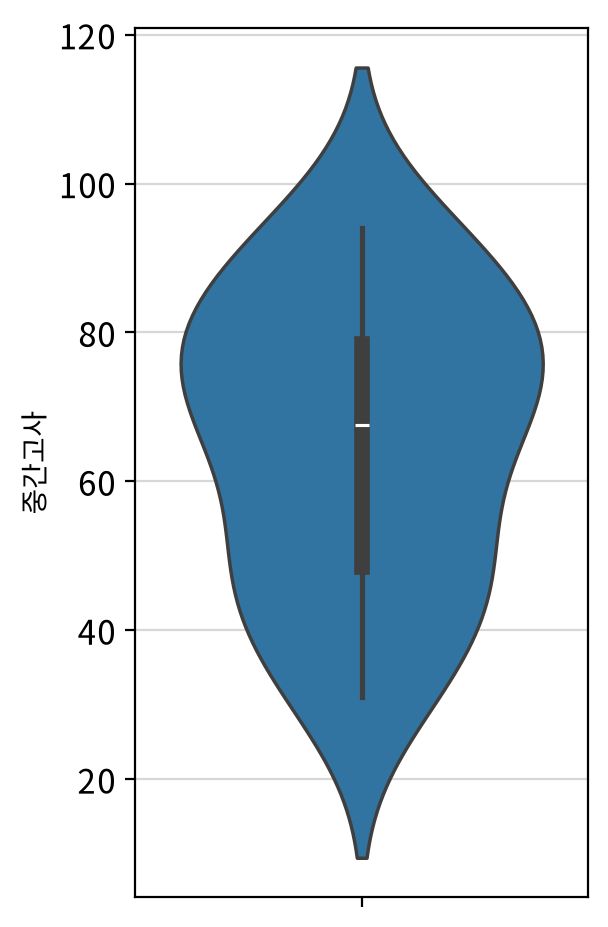

In [7]:
# 그래프 초기화
fig, ax = my_plot.init(width=320, height=480)

# 그래프 그리기
sb.violinplot(data=origin, y='중간고사')
ax.set_ylabel("중간고사", fontsize=10)

# 출력
my_plot.show()

6. 범주(hue) 지정

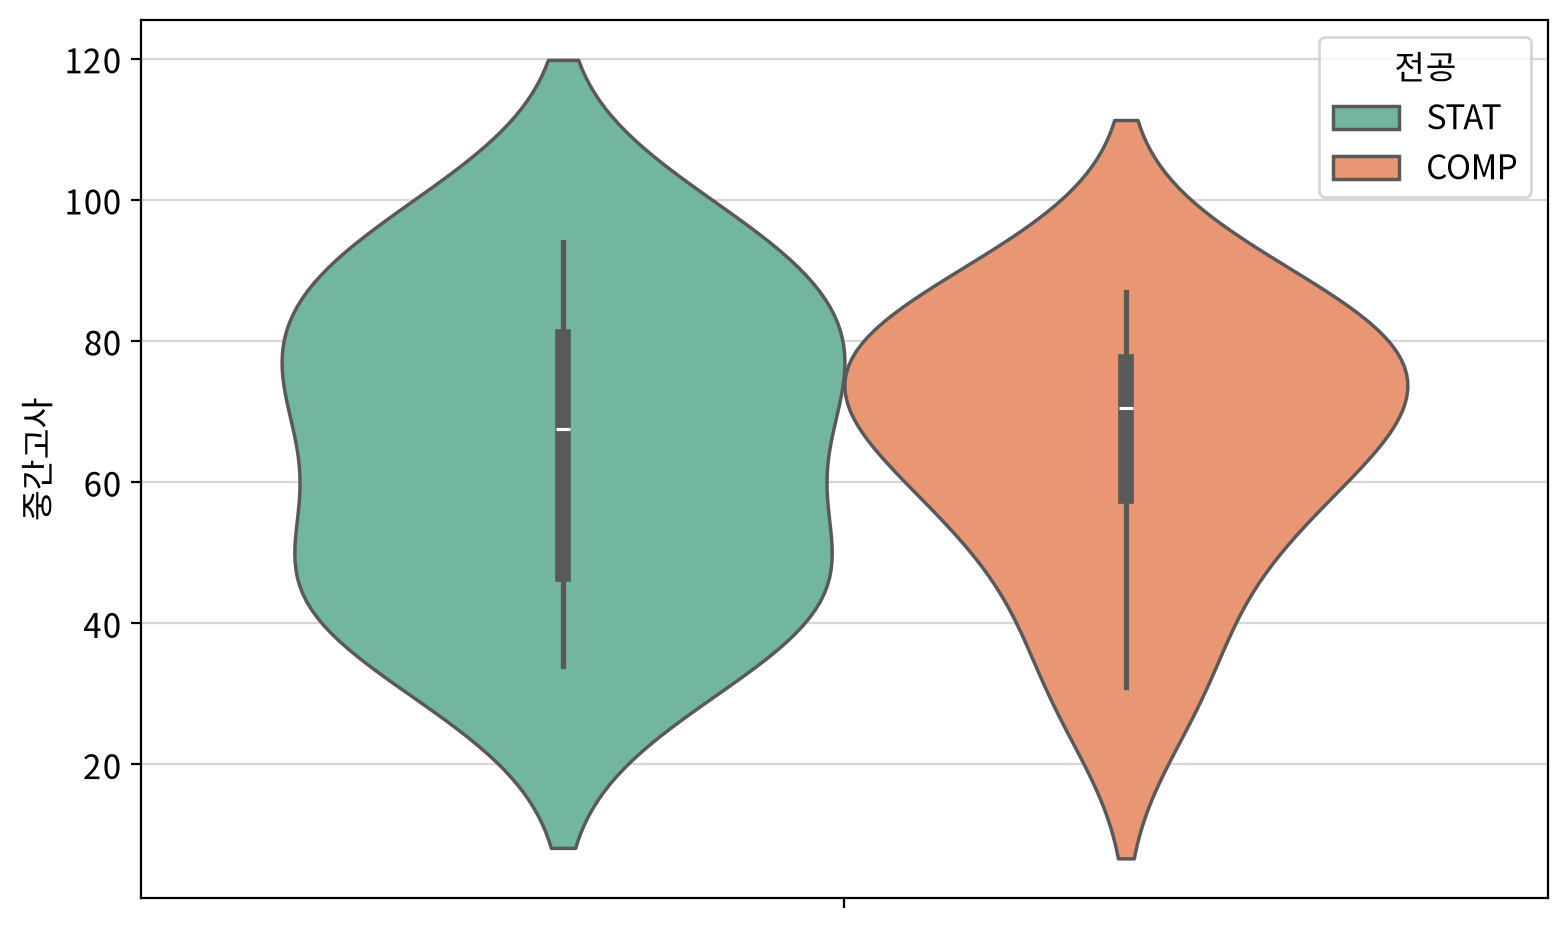

In [8]:
# 그래프 초기화
fig, ax = my_plot.init(width=800, height=480)

# 그래프 그리기
sb.violinplot(data=origin, y='중간고사', hue='전공', palette='Set2')

# 출력
my_plot.show()

> 인사이트
> - 전공별 중앙값 비교에서 COMP가 STAT보다 약간 높게 나타남
> - IQR(박스 구간)은 STAT가 더 넓어, 중간 50% 점수 변동 폭이 COMP보다 큼
> - 바이올린 폭 기준 분포 밀도는 두 전공 모두 70~80점대에서 상대적으로 두껍게 나타남
> - 저점 구간(약 30~50점대)에서는 STAT 쪽 폭이 더 두꺼워, 낮은 점수대 분포가 COMP보다 더 크게 보임
> - 전체 범위는 두 전공 모두 하단은 30점대 초반, 상단은 80~90점대까지 확인됨

### #03 모듈화 기능 확인

1. 상자그림 모듈화와 사용 방법이 동일하므로 여기서는 대표 사례 하나만 확인

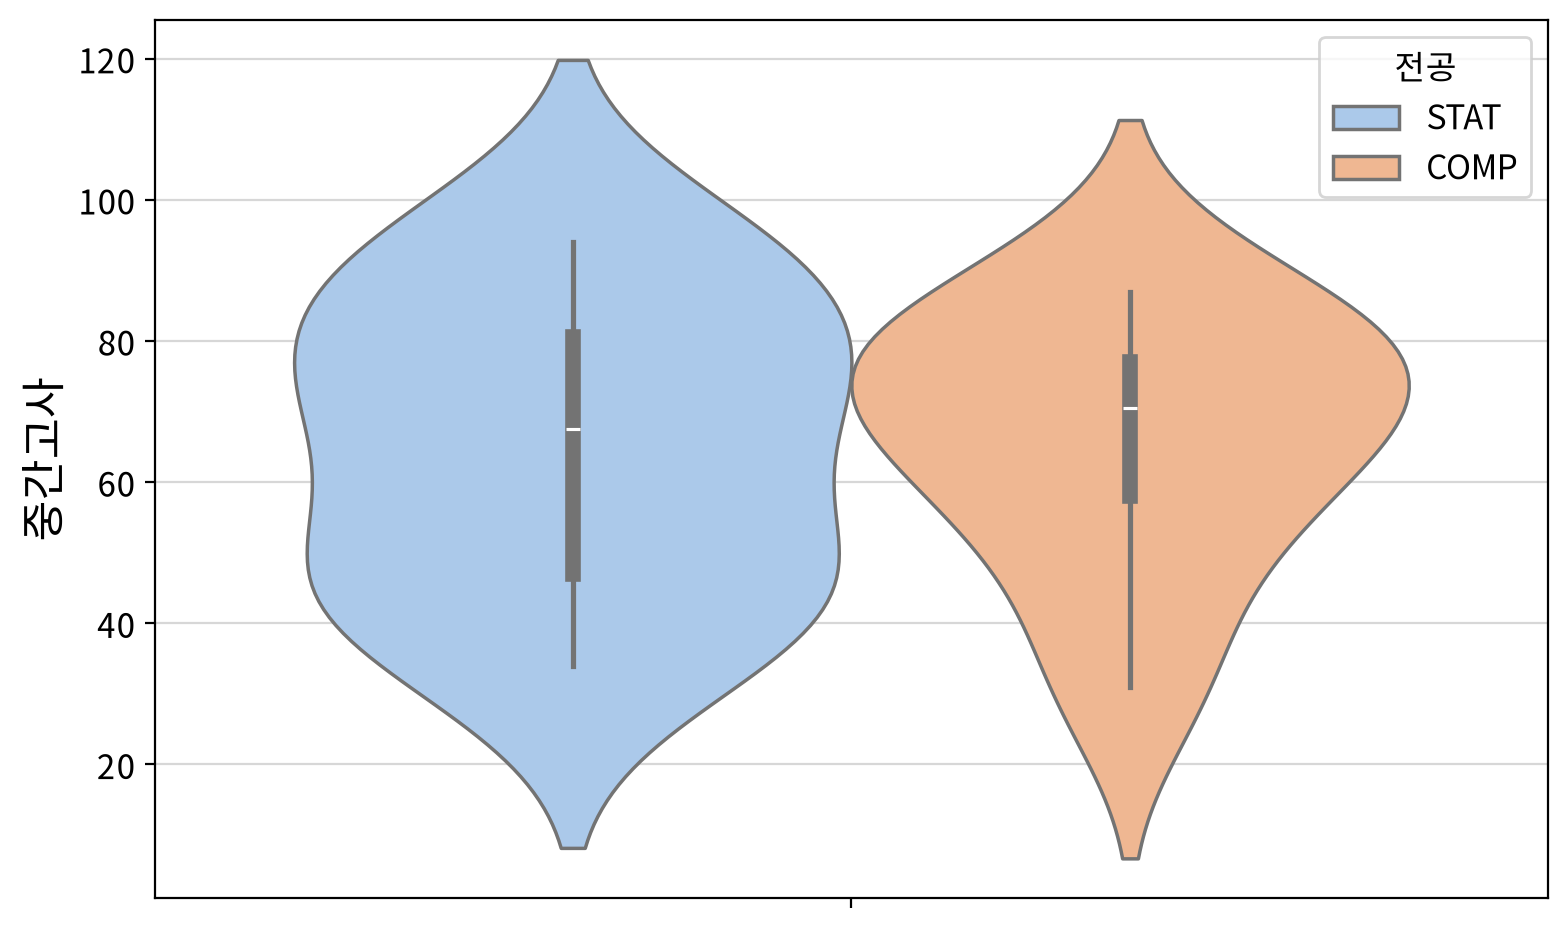

In [9]:
my_plot.violinplot(data=origin, y='중간고사', hue='전공',
                   ylabel="중간고사", width=800, height=480,
                   palette='pastel')

---

## 연습문제

### 버전에 따른 유저별 모바일 게임 이용시간 분포 비교하기

In [ ]:
# 라이브러리 참조
from jussam import load_data
from helpers import *
import seaborn as sb
from pandas import concat

In [11]:
# 데이터 불러오기
origin = load_data('cookie_cats')
origin.head()

📚 어느 모바일 게임의 버전에 따른 유저별 총 플레이 시간을 조사한 데이터 (출처: 방송통신대학교 통계학개론)


,version,sum_gamerounds
userid,,
116,A,3
337,A,38
377,B,165
483,B,1
488,B,179


In [15]:
# `version` 컬럼을 기준으로 데이터 나누기
Aver = origin[origin['version'] == 'A']
Bver = origin[origin['version'] == 'B']
display(Aver.head(), Bver.head())

,version,sum_gamerounds
userid,,
116,A,3
337,A,38
1066,A,0
2101,A,0
2179,A,39


,version,sum_gamerounds
userid,,
377,B,165
483,B,1
488,B,179
540,B,187
1444,B,2


In [17]:
# A 버전 데이터의 기술 통계량을 구해 이상치 경계값을 확인
desc_df = my_qtcheck.numerical_summary(Aver)
desc_df.T

,sum_gamerounds
count,44700.000
mean,52.456
std,256.716
min,0.000
25%,5.000
50%,17.000
75%,50.000
max,49854.000
rel_diff,2.086
rdiff_flag,large_diff


> 하한 -62.500, 상한 117.500

In [ ]:
# 이상치 경계 안쪽에 해당하는 행만 남도록 필터링
Aver_filt = Aver.query('-62.5 < sum_gamerounds < 117.5')
# Aver_filt = Aver_filt[(Aver_filt['sum_gamerounds'] >= desc_df['lower_bound']['sum_gamerounds']) & (Aver_filt['sum_gamerounds'] <= desc_df['upper_bound']['sum_gamerounds'])]
Aver_filt.head()

,version,sum_gamerounds
userid,,
116,A,3
337,A,38
1066,A,0
2101,A,0
2179,A,39


In [23]:
# B 버전 데이터의 기술 통계량을 구해 이상치 경계값을 확인
desc_df = my_qtcheck.numerical_summary(Bver)
desc_df.T

,sum_gamerounds
count,45489.000
mean,51.299
std,103.294
min,0.000
25%,5.000
50%,16.000
75%,52.000
max,2640.000
rel_diff,2.206
rdiff_flag,large_diff


> 하한 -65.500, 상한 122.500

In [ ]:
# 이상치 경계 안쪽에 해당하는 행만 남도록 필터링
Bver_filt = Bver.query('-65.5 < sum_gamerounds < 122.5')
# Bver_filt = Bver_filt[(Bver_filt['sum_gamerounds'] >= desc_df['lower_bound']['sum_gamerounds']) & (Bver_filt['sum_gamerounds'] <= desc_df['upper_bound']['sum_gamerounds'])]
Bver_filt.head()

,version,sum_gamerounds
userid,,
483,B,1
1444,B,2
1574,B,108
1842,B,3
2132,B,30


In [ ]:
# 이상치를 제거한 두 데이터를 하나의 데이터프레임으로 세로 병합
origin_filt = concat([Aver_filt, Bver_filt], ignore_index=True)
origin_filt

,version,sum_gamerounds
userid,,
116,A,3
337,A,38
1066,A,0
2101,A,0
2179,A,39
...,...,...
9998733,B,10
9999441,B,97
9999479,B,30


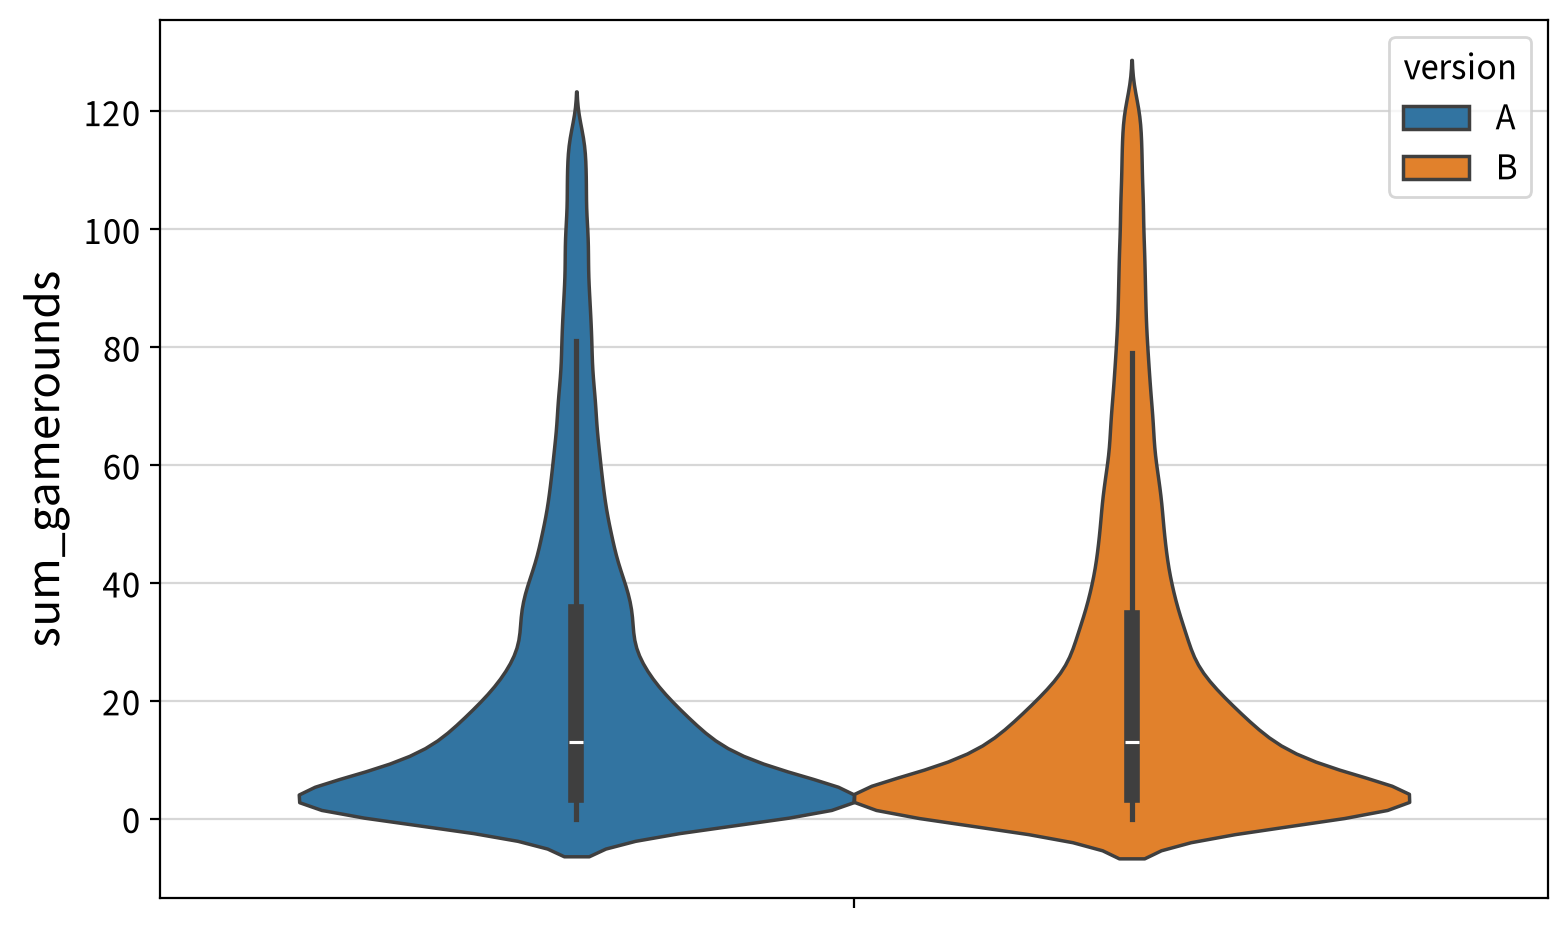

In [35]:
# 버전을 색상으로 구분하는 바이올린 플롯 그리기
my_plot.violinplot(data=origin_filt, y='sum_gamerounds', hue='version',
                   ylabel="sum_gamerounds", width=800, height=480)

### 답변
1. 두 버전의 바이올린 플롯에서 가로 두께(밀도)가 가장 두껍게 나타나는 플레이 시간 구간은 약 0~10이다.
2. 두 버전의 바이올린 모양을 통해 알 수 있는 분포의 비대칭 방향은 양의 왜도이다.
3. 두 버전의 바이올린을 비교했을 때 두 버전의 플레이 시간 분포는 유사하나, B버전의 플레이타임이 조금 더 긴 것으로 보여진다.
4. 버전업이 유저의 플레이 시간 증가에 유의미한 영향을 주었다고 볼 수 있다. 중앙값 뿐만 아니라 꼬리 길이가 증가한 것으로 보인다.

### 문제 풀이 (답안)

#### 문제 1

두 버전의 바이올린 플롯에서 가로 두께(밀도)가 가장 두껍게 나타나는 플레이 시간 구간은 어디인가?

- **정답**: 약 0 ~ 10회
- **해설**: 바이올린 플롯의 가로 폭은 해당 값 구간에 속하는 데이터의 밀도(빈도)를 의미한다. A 버전과 B 버전 모두 0 ~ 10회 부근에서 가장 두꺼운 폭을 보이고 있어, 두 버전 모두 대다수의 유저가 게임을 거의 하지 않았거나 10회 이내로 매우 적게 플레이한 뒤 이탈했음을 알 수 있다. 이는 모바일 게임에서 흔히 관찰되는 초기 이탈 유저 패턴이다.

#### 문제 2

두 버전의 바이올린 모양(아래는 두껍고 위로 갈수록 길고 가늘게 뻗는 형태)을 통해 알 수 있는 분포의 비대칭 방향(왜도)은?

- **정답**: 우측(양의 왜도, right-skewed)
- **해설**: 두 바이올린 모두 낮은 값(0 부근)에서 폭이 매우 넓고 높은 값으로 갈수록 폭이 좁아지면서 길게 꼬리를 형성하고 있다. 이는 분포가 오른쪽으로 긴 꼬리를 갖는 양의 왜도(positively skewed) 형태임을 의미한다. 즉 대다수 유저는 짧게 플레이하지만, 일부 소수의 유저가 매우 긴 플레이 시간을 기록하는 헤비 유저로 존재하여 평균을 끌어올리는 구조이다.

#### 문제 3

A 버전과 B 버전의 바이올린(분포 모양, 중앙값, 박스 위치, 꼬리 길이)을 비교했을 때 두 버전의 플레이 시간 분포 관계는?

- **정답**: 거의 유사함 (큰 차이 없음)
- **해설**: 두 바이올린의 최대 밀도 위치(약 0~10회), 내부 박스의 위치와 길이, 중앙값(약 13~15회), 위쪽 꼬리의 도달 지점이 모두 매우 비슷하게 나타난다. 따라서 A/B 테스트 결과 게임 버전 변경(A → B)은 유저의 총 플레이 시간 분포에 의미 있는 변화를 만들어내지 못했다고 해석할 수 있으며, 시각화만으로는 두 버전 간 유의미한 차이가 관찰되지 않는다.

#### 문제 4

A → B 버전업이 유저의 플레이 시간 증가에 유의미한 영향을 주었다고 볼 수 있는가?

- **정답**: 아니오 (유의미한 영향 없음)
- **해설**: 바이올린 플롯에서 두 버전의 분포 형태, 중앙값(약 13 ~ 15회), 박스(IQR) 위치와 길이, 꼬리의 도달 지점이 모두 거의 동일하게 나타난다. 즉 B 버전이 A 버전 대비 분포 전체가 위쪽(플레이 시간이 큰 방향)으로 이동했거나 박스 영역이 위로 올라간 현상이 보이지 않으므로, 버전업이 유저의 총 플레이 시간 증가에 유의미한 영향을 주었다고 해석할 근거는 시각화 결과에서 확인되지 않는다. (실제 결론을 위해서는 가설검정 등 통계적 검증을 함께 수행해야 한다.)
